In [1]:
#Question no.7#
import torch

r = torch.tensor(30000.1, dtype=torch.float64, requires_grad=True)
rs = 0.00887

tau = 2 * r * torch.sqrt(r / rs) * torch.sqrt(1 - rs / r)
tau.backward()

print("tau      =", tau.item())
print("dtau/dr  =", r.grad.item())

tau      = 110344877.04827532
dtau/dr  = 5517.226005413796


In [2]:
#Question no.8#
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import train_test_split, cross_val_score
from statistics import mean

# Read data
data = pd.read_csv("https://raw.githubusercontent.com/rahulbhadani/Datasets/refs/heads/master/RAV4/2020-04-15-05-12-00_2T3Y1RFV8KC014025_CAN_Messages_5_Hz.csv")
data.dropna(inplace=True) #remove drop na (not a number)
data.head()

,Clock,Time,speed,distance_covered,accely,yaw_rate,steer_rate,steer_angle,steer_fraction,wheel_speed_fl,wheel_speed_fr,wheel_speed_rl,wheel_speed_rr,lead_distance,acc_status,relative_vel
0,2020-04-15 12:12:01.074737152,1.586953e+09,74.53,4.997099,-0.10699,-0.072,0.0,0.0,-0.2,75.10,75.30,74.96,74.54,252.0,0.0,0.0
1,2020-04-15 12:12:01.274780160,1.586953e+09,74.76,18.868180,0.18013,-0.072,0.0,0.0,-0.4,74.81,74.63,74.43,74.60,252.0,0.0,0.0
2,2020-04-15 12:12:01.474822656,1.586953e+09,74.59,33.809555,0.03657,-0.316,0.0,0.0,-0.5,74.73,74.69,74.56,74.78,252.0,0.0,0.0
3,2020-04-15 12:12:01.674865664,1.586953e+09,74.59,48.761932,0.07246,-0.316,0.0,0.0,-0.5,74.99,74.97,75.16,74.71,252.0,0.0,0.0
4,2020-04-15 12:12:01.874908416,1.586953e+09,74.59,63.666958,-0.03521,-0.316,0.0,0.0,-0.5,74.85,75.06,74.45,74.42,252.0,0.0,0.0


In [3]:
#Making sure the data are presented in 2D#
X = data[["steer_angle"]]
y = data["yaw_rate"]

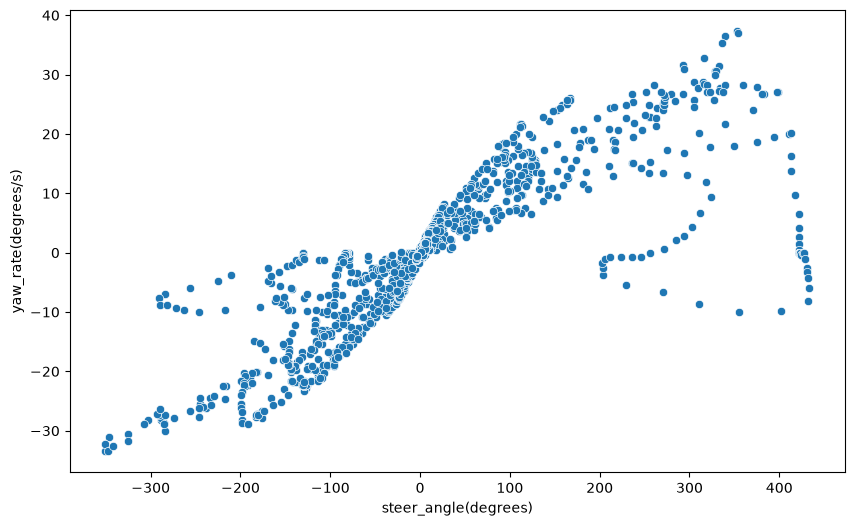

In [4]:
#Checking for linear relationship#
import seaborn as sns
fig, ax = plt.subplots(figsize=(10, 6))
# We will use seaborn for plotting
sns.scatterplot(x="steer_angle", y="yaw_rate", data=data, ax=ax)
fig.patch.set_alpha(0.0)
plt.xlabel("steer_angle(degrees)")
plt.ylabel("yaw_rate(degrees/s)")
plt.show()

In [5]:
#dividing train data and test data#
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.25)

In [6]:
linearModel = LinearRegression()
linearModel.fit(X_train, y_train)
# Evaluating the Linear Regression model on the test dataset
# coefficient of determination of the prediction
print(linearModel.score(X_test, y_test))

0.5620727141649089


In [7]:
# Predict yaw rate for a steering wheel angle of 100 degrees
new_data_point = pd.DataFrame({"steer_angle": [100]})
predicted_yaw = linearModel.predict(new_data_point)
print(f"Predicted yaw rate at 100 degrees: {predicted_yaw[0]:.2f} deg/s")

Predicted yaw rate at 100 degrees: 6.76 deg/s


In [8]:
print("Intercept (w0):", linearModel.intercept_)
print("Slope (w1):", linearModel.coef_[0])

Intercept (w0): -0.2052981535666989
Slope (w1): 0.06965866377796759


R^2 on test data: 0.4620
w0 = -3035.7601060043976
w1 = 11465.104916512078


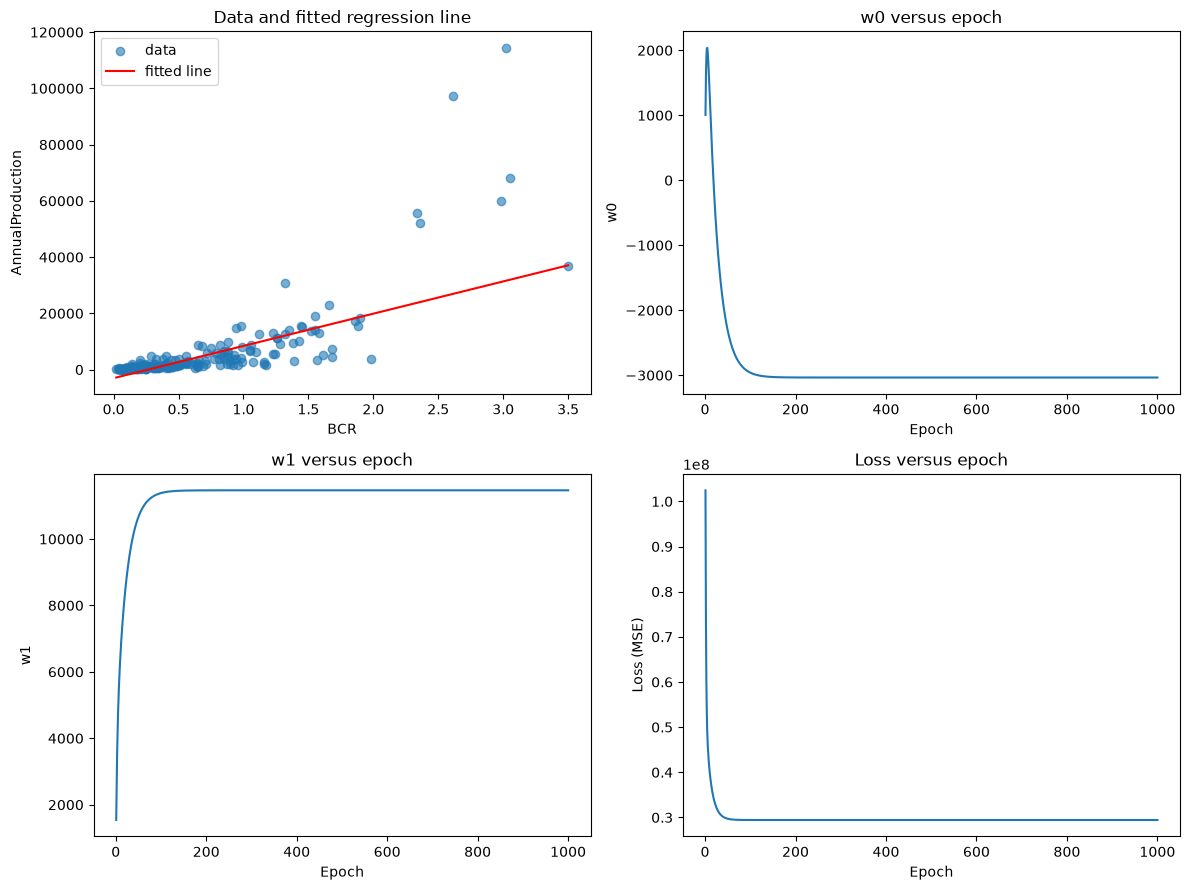

BCR = 1.0  -> 8429.34481050768
BCR = 0.5, 1.5, 2.5  -> [ 2696.79235225 14161.89726876 25627.00218528]


In [9]:
#Question no.9#
import pandas as pd
from sklearn.model_selection import train_test_split
from cherrynova.model import LinearRegression as CherryLinearRegression

# load the hydropower data
url = "https://raw.githubusercontent.com/rahulbhadani/Datasets/master/Hydropower.csv"
df_h = pd.read_csv(url)
X_h = df_h["BCR"]
y_h = df_h["AnnualProduction"]

# split into training and test data
X_h_train, X_h_test, y_h_train, y_h_test = train_test_split(
    X_h, y_h, test_size=0.25, random_state=42
)

# create a new model and train it
model = CherryLinearRegression(learning_rate=0.1, epochs=1000)
model.fit(X_h_train, y_h_train, X_h_test, y_h_test)
print("w0 =", model.w0.item())
print("w1 =", model.w1.item())

# plots and predictions
model.analysis_plot(X_h, y_h, xlabel="BCR", ylabel="AnnualProduction")
print("BCR = 1.0  ->", model.predict(1.0))
print("BCR = 0.5, 1.5, 2.5  ->", model.predict([0.5, 1.5, 2.5]))

Name: Maria Lubida
A-number:25369116